<a href="https://colab.research.google.com/github/rajnandini225/DAA-LAB/blob/main/trialproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
import os
import zipfile
import pandas as pd
from google.colab import files

uploaded = files.upload()

file_path = next(iter(uploaded))

if file_path.lower().endswith(".zip"):
    with zipfile.ZipFile(file_path, "r") as z:
        csv_files = [
            f for f in z.namelist()
            if f.lower().endswith(".csv")
            and not f.startswith("__MACOSX/")
        ]

        if not csv_files:
            raise ValueError("No CSV file found inside the ZIP archive.")

        print("CSV files found:", csv_files)

        # Load the first CSV from the archive
        with z.open(csv_files[0]) as f:
            df = pd.read_csv(f)

elif file_path.lower().endswith(".csv"):
    df = pd.read_csv(file_path)

else:
    raise ValueError("Please upload a CSV or ZIP file.")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Saving Combined Data.csv.zip to Combined Data.csv.zip
CSV files found: ['Combined Data.csv']
Dataset loaded successfully!
Shape: (53043, 3)


,Unnamed: 0,statement,status
0,0,oh my gosh,Anxiety
1,1,"trouble sleeping, confused mind, restless hear...",Anxiety
2,2,"All wrong, back off dear, forward doubt. Stay ...",Anxiety
3,3,I've shifted my focus to something else but I'...,Anxiety
4,4,"I'm restless and restless, it's been a month n...",Anxiety


In [3]:
# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Check required columns
required = {"statement", "status"}

if not required.issubset(df.columns):
    raise ValueError(
        f"Required columns are {required}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Keep only the relevant columns
df = df[["statement", "status"]].copy()

# Remove missing values
df = df.dropna(subset=["statement", "status"])

# Convert to strings and remove surrounding whitespace
df["statement"] = df["statement"].astype(str).str.strip()
df["status"] = df["status"].astype(str).str.strip()

# Remove empty records
df = df[
    (df["statement"] != "") &
    (df["status"] != "")
]

# Remove duplicate statement-label pairs
df = df.drop_duplicates(subset=["statement", "status"])

df = df.reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("\nClass distribution:")
print(df["status"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

display(df.head())

Cleaned dataset shape: (51093, 2)

Class distribution:
status
Normal                  16040
Depression              15094
Suicidal                10644
Anxiety                  3623
Bipolar                  2501
Stress                   2296
Personality disorder      895
Name: count, dtype: int64

Missing values:
statement    0
status       0
dtype: int64


,statement,status
0,oh my gosh,Anxiety
1,"trouble sleeping, confused mind, restless hear...",Anxiety
2,"All wrong, back off dear, forward doubt. Stay ...",Anxiety
3,I've shifted my focus to something else but I'...,Anxiety
4,"I'm restless and restless, it's been a month n...",Anxiety


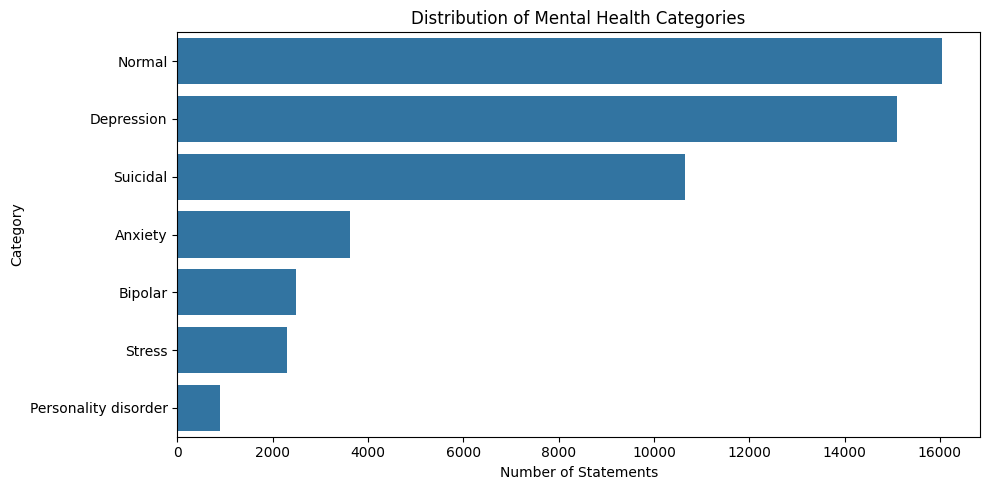

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    y="status",
    order=df["status"].value_counts().index
)

plt.title("Distribution of Mental Health Categories")
plt.xlabel("Number of Statements")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

X = df["statement"]
y = df["status"]

# Split before feature extraction to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Categories:", sorted(y.unique()))

Training samples: 40874
Testing samples: 10219
Categories: ['Anxiety', 'Bipolar', 'Depression', 'Normal', 'Personality disorder', 'Stress', 'Suicidal']


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

models = {
    "Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Linear SVC": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

pipelines = {}

for name, classifier in models.items():
    pipelines[name] = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=50000,
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", classifier)
    ])

print("ML pipelines created successfully.")

ML pipelines created successfully.


In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = []
trained_models = {}

for name, pipeline in pipelines.items():

    print(f"\nTraining {name}...")

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1
    })

    trained_models[name] = pipeline

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {f1:.4f}")

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON")
display(results_df.round(4))


Training Naive Bayes...
Accuracy: 0.6484
Macro F1: 0.4056

Training Logistic Regression...
Accuracy: 0.7710
Macro F1: 0.7192

Training Linear SVC...
Accuracy: 0.7732
Macro F1: 0.7191

MODEL COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.7710,0.7011,0.7480,0.7192
1,Linear SVC,0.7732,0.7353,0.7077,0.7191
2,Naive Bayes,0.6484,0.8509,0.3837,0.4056


In [8]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model:", best_model_name)
print(
    "Best macro F1-score:",
    round(results_df.iloc[0]["Macro F1"], 4)
)

Best model: Logistic Regression
Best macro F1-score: 0.7192


In [9]:
from sklearn.metrics import classification_report

y_pred = best_model.predict(X_test)

print("Selected model:", best_model_name)
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Selected model: Logistic Regression

Classification Report:

                      precision    recall  f1-score   support

             Anxiety       0.76      0.83      0.79       725
             Bipolar       0.73      0.77      0.75       500
          Depression       0.79      0.62      0.69      3019
              Normal       0.90      0.93      0.91      3208
Personality disorder       0.54      0.61      0.57       179
              Stress       0.50      0.73      0.60       459
            Suicidal       0.68      0.76      0.72      2129

            accuracy                           0.77     10219
           macro avg       0.70      0.75      0.72     10219
        weighted avg       0.78      0.77      0.77     10219



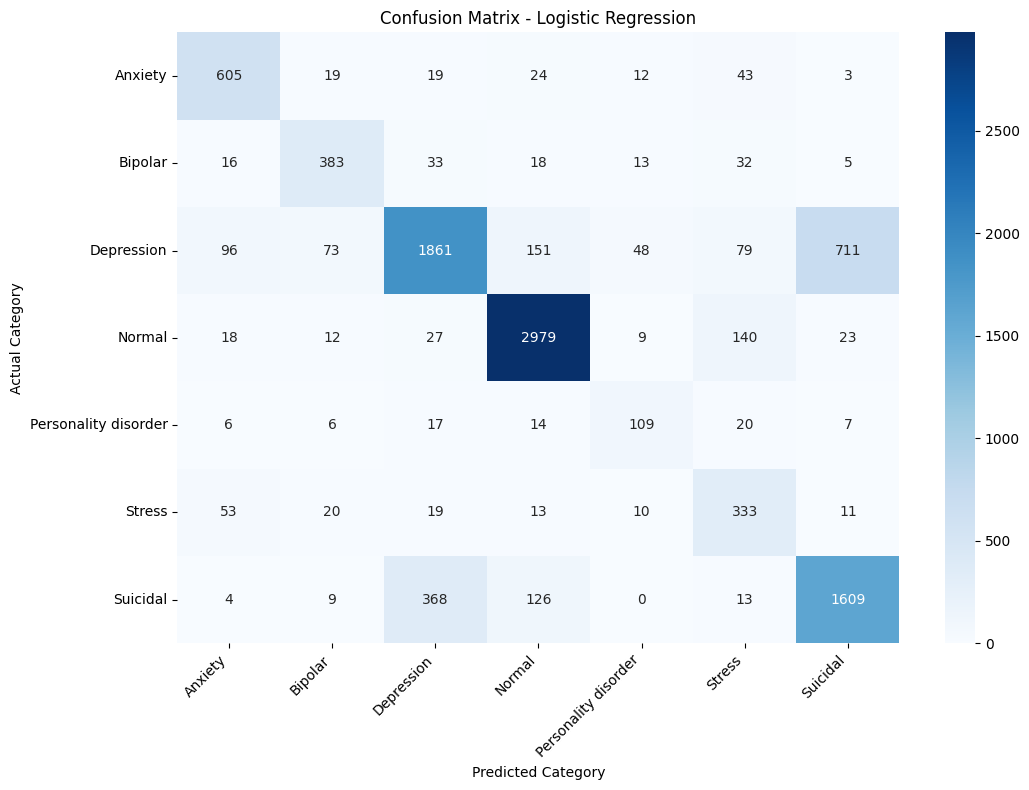

In [10]:
from sklearn.metrics import confusion_matrix

labels = best_model.named_steps["classifier"].classes_

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
def predict_mental_health_category(statement):
    if not isinstance(statement, str) or not statement.strip():
        return "Please enter a valid statement."

    prediction = best_model.predict([statement])[0]

    print("Statement:", statement)
    print("Predicted category:", prediction)

    return prediction


predict_mental_health_category(
    "I have been feeling worried and unable to sleep lately."
)

Statement: I have been feeling worried and unable to sleep lately.
Predicted category: Anxiety


'Anxiety'

In [12]:
import joblib

model_filename = "mental_health_ml_model.joblib"

joblib.dump(best_model, model_filename)

print("Model saved as:", model_filename)

Model saved as: mental_health_ml_model.joblib


In [14]:
from google.colab import files

files.download("mental_health_ml_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
import joblib

loaded_model = joblib.load("mental_health_ml_model.joblib")

text = "I feel nervous and worried about everything."

prediction = loaded_model.predict([text])[0]

print("Predicted category:", prediction)

Predicted category: Anxiety


In [16]:
results_df.to_csv(
    "mental_health_model_comparison.csv",
    index=False
)

files.download("mental_health_model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>